### **BAGIAN 3 : HISTOGRAM DAN PERBAIKAN CITRA**

---

Tujuan bagian: membaca mutu citra dari histogram, menerapkan operasi titik serta
ekualisasi, dan memilih perbaikan yang benar-benar membantu pemisahan bercak, bukan
sekadar membuat citra tampak lebih indah.

In [9]:
from google.colab import drive
import os
import sys

drive.mount('/content/drive')
BASE_DIR = "/content/drive/MyDrive/simuteh-1032"
os.chdir(BASE_DIR)
sys.path.append(os.path.join(BASE_DIR, "src"))

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak, statistik

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


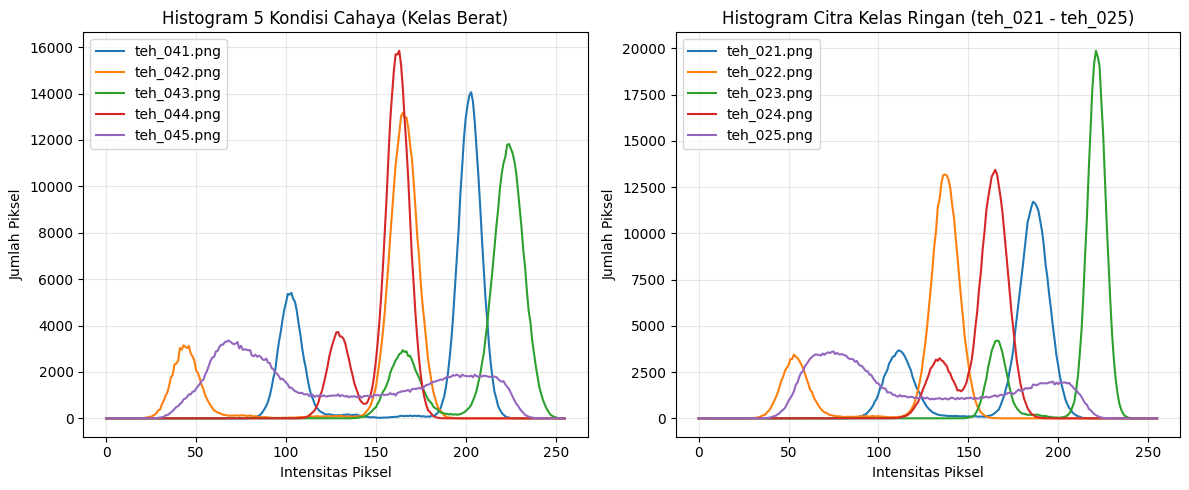

=== Tabel Statistik Diagnosis Mutu Citra (Langkah 3.2) ===
     nama_file  rerata  simpangan_baku  min  maks  persen_gelap  persen_terang
0  teh_041.png   173.5            45.2   69   228           0.0           21.3
1  teh_042.png   141.9            48.1    9   199          14.2            0.0
2  teh_043.png   212.1            24.6  128   253           0.0           78.2
3  teh_044.png   155.8            14.3  104   190           0.0            0.0
4  teh_045.png   126.7            57.6   25   241           3.6           12.3
5  teh_021.png   168.3            33.1   77   220           0.0            0.7
6  teh_022.png   120.2            34.2   15   172           5.7            0.0
7  teh_023.png   211.1            21.9  143   243           0.0           81.0
8  teh_024.png   158.5            14.2  102   197           0.0            0.0
9  teh_025.png   120.6            51.5   31   232           1.0            5.5


In [11]:
# 3.2 Diagnosis Mutu Citra 5 Kondisi Cahaya
from utils_cv import statistik, baca
import cv2
import pandas as pd
import matplotlib.pyplot as plt

# 1. Daftar 5 citra beda kondisi (Kelas Berat) dan 5 citra Kelas Ringan
citra_berat = ["teh_041.png", "teh_042.png", "teh_043.png", "teh_044.png", "teh_045.png"]
citra_ringan = ["teh_021.png", "teh_022.png", "teh_023.png", "teh_024.png", "teh_025.png"]

data_tabel = []

# --- PLOT HISTOGRAM KELAS BERAT (5 KONDISI CAHAYA) ---
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
for nama in citra_berat:
    gray = cv2.cvtColor(baca(f"data/sintetis/citra/{nama}"), cv2.COLOR_BGR2GRAY)
    stat = statistik(gray)
    stat["nama_file"] = nama
    data_tabel.append(stat)

    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    plt.plot(hist, label=nama)

plt.title("Histogram 5 Kondisi Cahaya (Kelas Berat)")
plt.xlabel("Intensitas Piksel")
plt.ylabel("Jumlah Piksel")
plt.legend()
plt.grid(True, alpha=0.3)

# --- PLOT HISTOGRAM KELAS RINGAN (teh_021 s.d. teh_025) ---
plt.subplot(1, 2, 2)
for nama in citra_ringan:
    gray = cv2.cvtColor(baca(f"data/sintetis/citra/{nama}"), cv2.COLOR_BGR2GRAY)
    stat = statistik(gray)
    stat["nama_file"] = nama
    data_tabel.append(stat)

    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    plt.plot(hist, label=nama)

plt.title("Histogram Citra Kelas Ringan (teh_021 - teh_025)")
plt.xlabel("Intensitas Piksel")
plt.ylabel("Jumlah Piksel")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("hasil/b3_histogram_diagnosis.png")
plt.show()

# --- CETAK TABEL STATISTIK DIAGNOSIS ---
df_diag = pd.DataFrame(data_tabel)
print("=== Tabel Statistik Diagnosis Mutu Citra (Langkah 3.2) ===")
print(df_diag[["nama_file", "rerata", "simpangan_baku", "min", "maks", "persen_gelap", "persen_terang"]])

=== Kontras Bercak (KB) Citra Bayangan (teh_045) ===
asli       | KB: 1.02 | Std: 57.6
negatif    | KB: 1.02 | Std: 57.6
cerah+50   | KB: 1.02 | Std: 55.5
kontras    | KB: 1.02 | Std: 80.6
regang     | KB: 1.05 | Std: 81.7
gamma0.5   | KB: 0.91 | Std: 41.5
gamma1.8   | KB: 1.20 | Std: 62.2
ekualisasi | KB: 0.84 | Std: 73.5
CLAHE      | KB: 1.70 | Std: 48.0


/tmp/ipykernel_3057/88236112.py:47: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(hasil[m].ravel(), 256, [0, 256], color='blue', alpha=0.7)


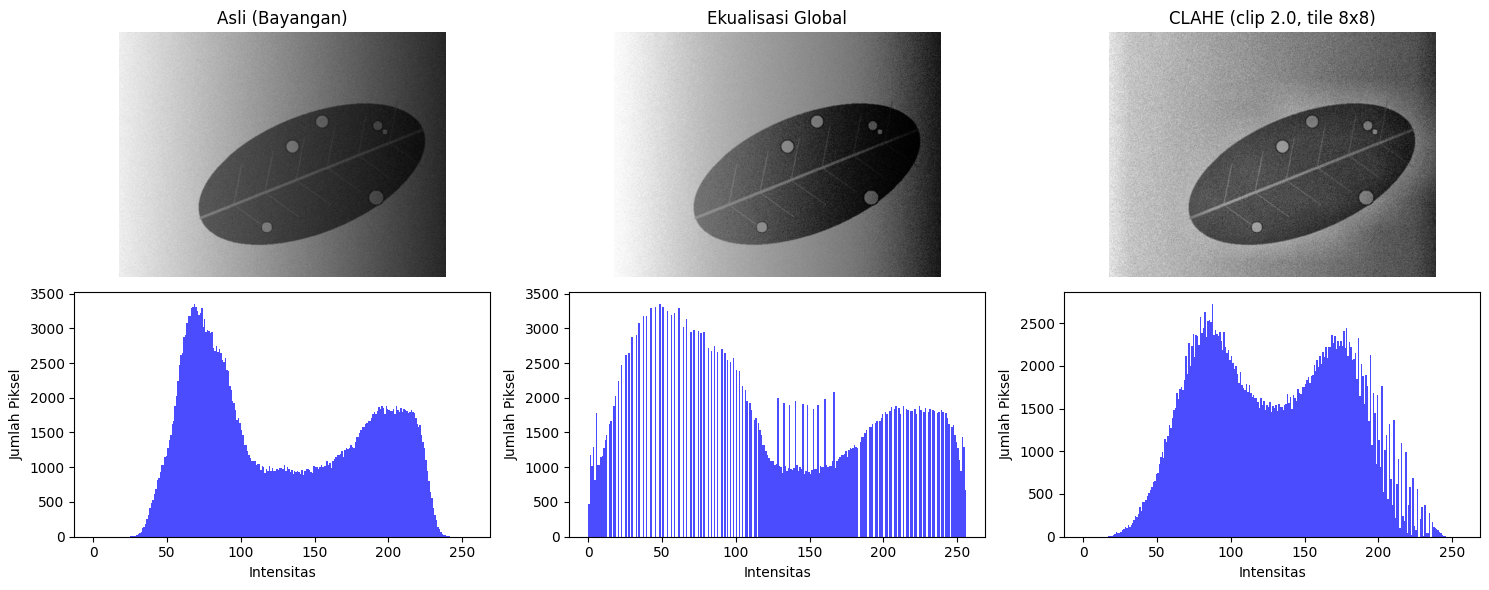

In [12]:
# 3.3 Perbaikan Citra Kondisi Bayangan & Tabel KB

nama = "teh_045.png" # Kondisi bayangan
img = baca(f"data/sintetis/citra/{nama}")
md = cv2.imread(f"data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"data/sintetis/mask_bercak/{nama}", 0)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

def gamma_lut(g):
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return lut.clip(0, 255).astype(np.uint8)

rmin, rmax = np.percentile(gray, (2, 98))

hasil = {
    "asli": gray,
    "negatif": 255 - gray,
    "cerah+50": cv2.add(gray, 50),
    "kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40),
    "regang": np.clip((gray - rmin) / (rmax - rmin) * 255, 0, 255).astype(np.uint8),
    "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)),
    "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)),
    "ekualisasi": cv2.equalizeHist(gray),
    "CLAHE": cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)
}

data_kb = []
print("=== Kontras Bercak (KB) Citra Bayangan (teh_045) ===")
for nm, c in hasil.items():
    kb_val = kontras_bercak(c, md, mb)
    std_val = c.std()
    print(f"{nm:10s} | KB: {kb_val:.2f} | Std: {std_val:.1f}")
    data_kb.append({"Metode": nm, "KB": round(kb_val, 2), "Simpangan_Baku": round(std_val, 1)})

# Plot visual perbandingan Asli vs Ekualisasi Global vs CLAHE
plt.figure(figsize=(15, 6))
metode_tampil = ["asli", "ekualisasi", "CLAHE"]
judul_tampil = ["Asli (Bayangan)", "Ekualisasi Global", "CLAHE (clip 2.0, tile 8x8)"]

for idx, (m, j) in enumerate(zip(metode_tampil, judul_tampil)):
    plt.subplot(2, 3, idx + 1)
    plt.imshow(hasil[m], cmap="gray")
    plt.title(j)
    plt.axis("off")

    plt.subplot(2, 3, idx + 4)
    plt.hist(hasil[m].ravel(), 256, [0, 256], color='blue', alpha=0.7)
    plt.xlabel("Intensitas")
    plt.ylabel("Jumlah Piksel")

plt.tight_layout()
plt.savefig("hasil/b3_perbandingan_clahe.png")
plt.show()

=== EXPERIMEN PARAMETER CLAHE ===
clip=1.0 tile= 4 : KB=1.66
clip=1.0 tile= 8 : KB=1.64
clip=1.0 tile=16 : KB=1.65
clip=2.0 tile= 4 : KB=1.80
clip=2.0 tile= 8 : KB=1.70
clip=2.0 tile=16 : KB=1.71
clip=4.0 tile= 4 : KB=1.84
clip=4.0 tile= 8 : KB=1.57
clip=4.0 tile=16 : KB=1.67


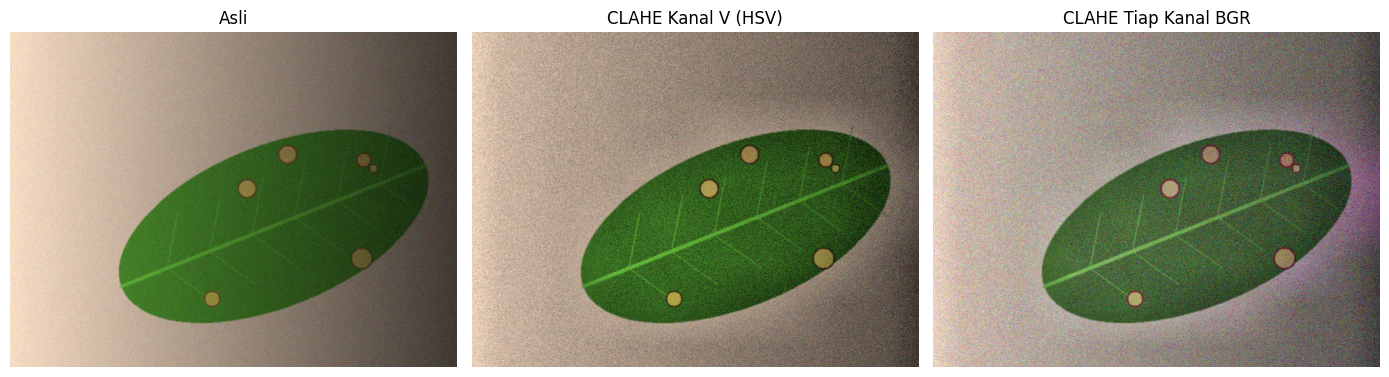

In [13]:
# 3.4 Eksperimen Parameter CLAHE & CLAHE pada Citra Warna
print("=== EXPERIMEN PARAMETER CLAHE ===")
for clip in [1.0, 2.0, 4.0]:
    for tile in [4, 8, 16]:
        c = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(gray)
        print(f"clip={clip} tile={tile:2d} : KB={kontras_bercak(c, md, mb):.2f}")

# CLAHE pada citra warna: Kanal V vs Tiap Kanal BGR
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
via_v = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

via_bgr = cv2.merge([clahe.apply(c) for c in cv2.split(img)])

tampil([img, via_v, via_bgr], ["Asli", "CLAHE Kanal V (HSV)", "CLAHE Tiap Kanal BGR"], baris=1, ukuran=(14, 4))
plt.savefig("hasil/b3_clahe_warna.png")
plt.show()
